# Importing The Important Libraries

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

import joblib

# Understanding The Features
- age -- Age of the person
- sex -- Male/Female
- bmi -- Body Mass Index
- children -- Number of children/dependents
- smoker -- Yes/No
- region -- US region
- charges -- Medical insurance cost

# Reading The Dataset

In [2]:
df = pd.read_csv('./insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# EDA

## Basic EDA
- How many rows and columns are in the dataset?
- What are the data types of each feature?
- Are there any missing values?
- Are there any duplicated rows?
- What are the unique values of each categorical feature?
- What are the minimum, maximum, mean, and median values of the numerical features?
- What is the distribution of charges?

In [3]:
df.shape

(1338, 7)

In [4]:
print(df.dtypes)

numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.to_list()
categorical_features = df.select_dtypes(include='object').columns.to_list()
print(numerical_features)
print(categorical_features)

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object
['age', 'bmi', 'children', 'charges']
['sex', 'smoker', 'region']


C:\Users\DT 2003\AppData\Local\Temp\ipykernel_10536\775506784.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include='object').columns.to_list()


In [5]:
df.isna().sum().sum()

np.int64(0)

In [6]:
df.duplicated().sum()

np.int64(1)

In [7]:
for feature in categorical_features:
  print(feature, ':')
  print(df[feature].unique())

sex :
<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
smoker :
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
region :
<ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [8]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


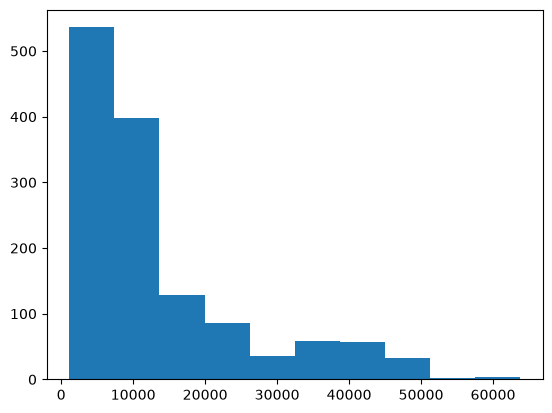

1.5158796580240388


In [9]:
plt.hist(df['charges'])
plt.show()
print(df['charges'].skew())

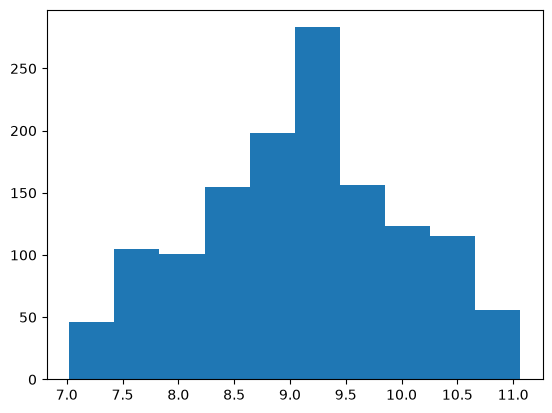

In [10]:
plt.hist(np.log(df['charges']))
plt.show()

## Univariate Analysis
- What is the age distribution of the customers?
- What is the BMI distribution?
- How many customers are smokers vs. non-smokers?
- How are customers distributed across the different regions?
- How many children does each customer have?
- Is the charges distribution symmetric or skewed?

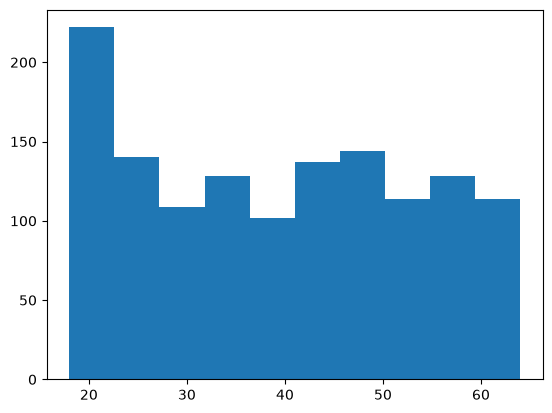

0.055672515652992825


In [11]:
plt.hist(df['age'])
plt.show()
print(df['age'].skew())

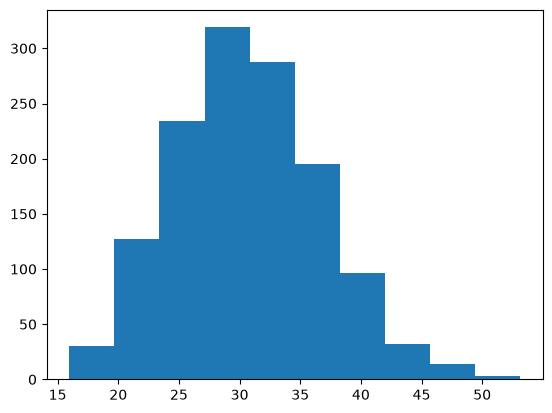

0.28404711059874543


In [12]:
plt.hist(df['bmi'])
plt.show()
print(df['bmi'].skew())

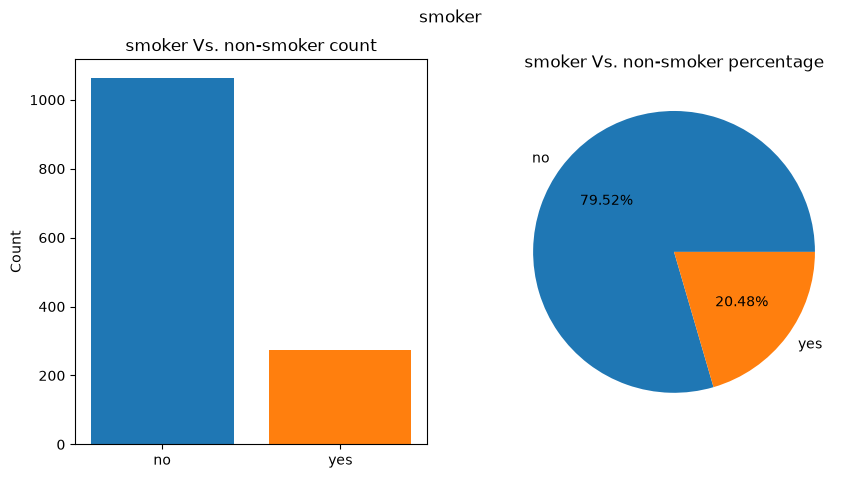

In [13]:
smoker = df['smoker'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].bar(smoker.index, smoker, color=['tab:blue', 'tab:orange'])
axes[0].set_title('smoker Vs. non-smoker count')
axes[0].set_ylabel('Count')
axes[1].pie(smoker, autopct='%0.2f%%',labels = smoker.index)
axes[1].set_title('smoker Vs. non-smoker percentage')
fig.suptitle('smoker')
plt.show()

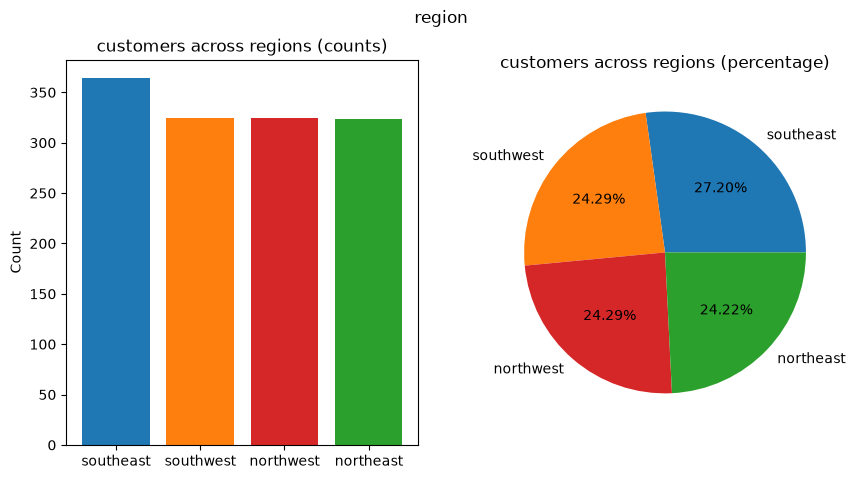

In [14]:
region = df['region'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
colors = ['tab:blue', 'tab:orange', 'tab:red', 'tab:green']
axes[0].bar(region.index, region, color=colors)
axes[0].set_title('customers across regions (counts)')
axes[0].set_ylabel('Count')
axes[1].pie(region, autopct='%0.2f%%',labels = region.index, colors=colors)
axes[1].set_title('customers across regions (percentage)')
fig.suptitle('region')
plt.show()

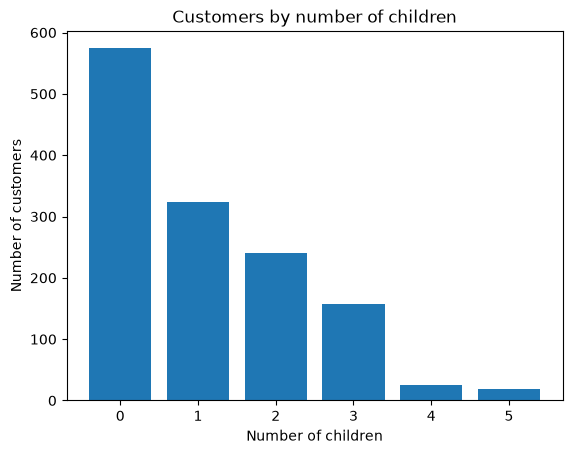

In [15]:
children = df['children'].value_counts().sort_index()
plt.bar(children.index, children)
plt.xlabel('Number of children')
plt.ylabel('Number of customers')
plt.title('Customers by number of children')
plt.show()

In [16]:
print('right skewed')

right skewed


## Relationship Analysis
- Does age have a relationship with medical charges?
- Does BMI have a relationship with medical charges?
- Do smokers have higher medical charges than non-smokers?
- Are medical charges different between males and females?
- Does the number of children affect medical charges?
- Are medical charges different across regions?
- Does age differ between smokers and non-smokers?
- Is BMI different between smokers and non-smokers?

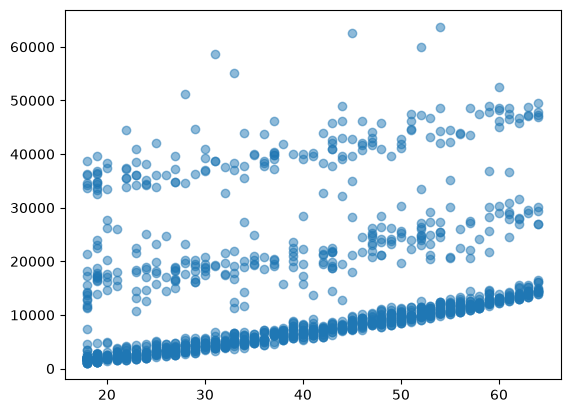

There is a weak overall relationship between age and charges (r = 0.30)


In [17]:
plt.scatter(df['age'], df['charges'], alpha=0.5)
plt.show()
age_charges_corr = df['age'].corr(df['charges'])
print(f"There is a weak overall relationship between age and charges (r = {age_charges_corr:.2f})")

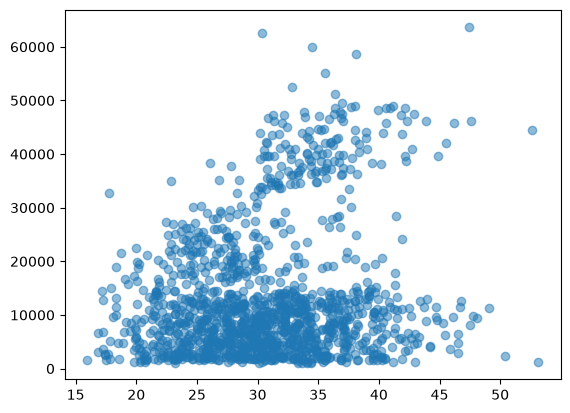

There is a weak overall relationship between bmi and charges (r = 0.20)


In [18]:
plt.scatter(df['bmi'], df['charges'], alpha=0.5)
plt.show()
bmi_charges_corr = df['bmi'].corr(df['charges'])
print(f"There is a weak overall relationship between bmi and charges (r = {bmi_charges_corr:.2f})")

In [19]:
median_charges_across_smoker = df.groupby('smoker')['charges'].median()
print(median_charges_across_smoker)
ratio = median_charges_across_smoker['yes'] / median_charges_across_smoker['no']
print(f"Smokers have much higher medical charges than non-smokers "
      f"(median {median_charges_across_smoker['yes']:,.0f} vs {median_charges_across_smoker['no']:,.0f}, about {ratio:.1f}x higher).")

smoker
no      7345.40530
yes    34456.34845
Name: charges, dtype: float64
Smokers have much higher medical charges than non-smokers (median 34,456 vs 7,345, about 4.7x higher).


In [20]:
median_charges_across_sex = df.groupby('sex')['charges'].median()
median_charges_across_sex

sex
female    9412.96250
male      9369.61575
Name: charges, dtype: float64

In [21]:
median_charges_across_children = df.groupby('children')['charges'].median()
median_charges_across_children

children
0     9856.95190
1     8483.87015
2     9264.97915
3    10600.54830
4    11033.66170
5     8589.56505
Name: charges, dtype: float64

In [22]:
median_charges_across_region = df.groupby('region')['charges'].median()
median_charges_across_region

region
northeast    10057.652025
northwest     8965.795750
southeast     9294.131950
southwest     8798.593000
Name: charges, dtype: float64

In [23]:
median_age_across_smoker = df.groupby('smoker')['age'].median()
median_age_across_smoker

smoker
no     40.0
yes    38.0
Name: age, dtype: float64

In [24]:
median_bmi_across_smoker = df.groupby('smoker')['bmi'].median()
median_bmi_across_smoker

smoker
no     30.3525
yes    30.4475
Name: bmi, dtype: float64

## Deeper EDA
- How does smoking status affect the relationship between age and charges?
- How does smoking status affect the relationship between BMI and charges?
- Are there particular age groups with unusually high medical costs?
- Are there outliers in charges? If so, what characteristics do those customers have?
- Are there interactions between smoker, age, and bmi that appear to explain high charges?
- Which numerical features have the strongest correlation with charges?
- Can you identify a group of customers with exceptionally high medical costs? - What do they have in common?

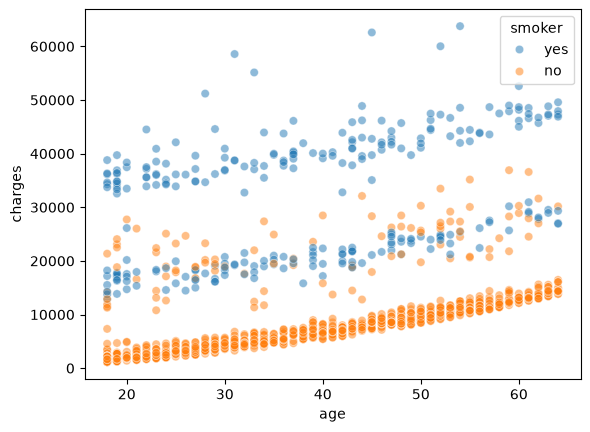

In [25]:
sns.scatterplot(x='age',y='charges', hue='smoker', data=df, alpha=0.5)
plt.show()

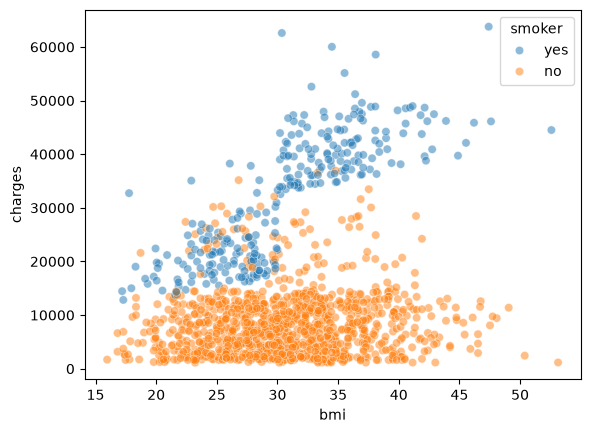

In [26]:
sns.scatterplot(x='bmi',y='charges', hue='smoker', data=df, alpha=0.5)
plt.show()

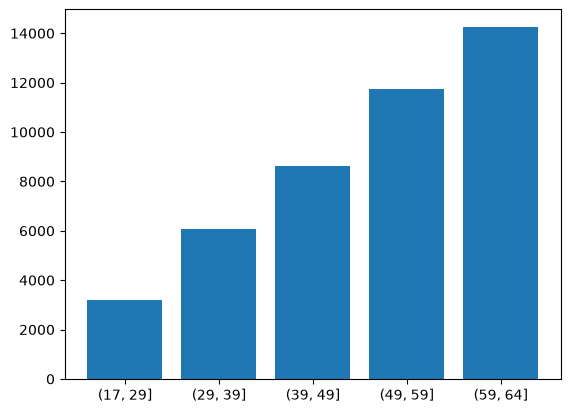

In [27]:
bins = [17, 29, 39, 49, 59, 64]
age_bins = pd.cut(df['age'], bins=bins)
df['age_bins'] = age_bins
age_bins_charges = df.groupby('age_bins')['charges'].median()
plt.bar(age_bins_charges.index.astype(str), age_bins_charges)
plt.show()

In [28]:
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df['charges'] < lower) | (df['charges'] > upper)]
print(len(outliers))

139


In [29]:
outliers.describe()

,age,bmi,children,charges
count,139.000000,139.000000,139.000000,139.000000
mean,41.079137,35.564604,1.187050,42103.947206
std,13.801420,4.434917,1.126546,5582.168107
min,18.000000,22.895000,0.000000,34617.840650
25%,30.000000,32.667500,0.000000,37786.149950
50%,43.000000,35.200000,1.000000,40974.164900
75%,52.500000,37.660000,2.000000,45786.706425
max,64.000000,52.580000,4.000000,63770.428010


In [30]:
non_outliers = df[df['charges'].between(lower, upper)]
non_outliers.describe()

,age,bmi,children,charges
count,1199.000000,1199.000000,1199.000000,1199.000000
mean,38.989992,30.095200,1.084237,9927.753402
std,14.068040,6.010551,1.214304,7241.158309
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,25.800000,0.000000,4408.695900
50%,39.000000,29.735000,1.000000,8410.046850
75%,51.000000,33.820000,2.000000,12953.594600
max,64.000000,53.130000,5.000000,34472.841000


In [31]:
print("for numerical features, age and bmi can have meaningful insights between outliers and non-outliers")

for numerical features, age and bmi can have meaningful insights between outliers and non-outliers


In [32]:
for feature in outliers.columns:
  if feature in categorical_features:
    print(outliers[feature].value_counts(normalize=True) * 100)

sex
male      64.028777
female    35.971223
Name: proportion, dtype: float64
smoker
yes    97.841727
no      2.158273
Name: proportion, dtype: float64
region
southeast    41.007194
southwest    24.460432
northeast    20.143885
northwest    14.388489
Name: proportion, dtype: float64


In [33]:
for feature in non_outliers.columns:
  if feature in categorical_features:
    print(non_outliers[feature].value_counts(normalize=True) * 100)

sex
female    51.042535
male      48.957465
Name: proportion, dtype: float64
smoker
no     88.490409
yes    11.509591
Name: proportion, dtype: float64
region
southeast    25.604671
northwest    25.437865
northeast    24.687239
southwest    24.270225
Name: proportion, dtype: float64


In [34]:
print("for categorical features, all features have differ between outliers and non-outliers especially smoker")

for categorical features, all features have differ between outliers and non-outliers especially smoker


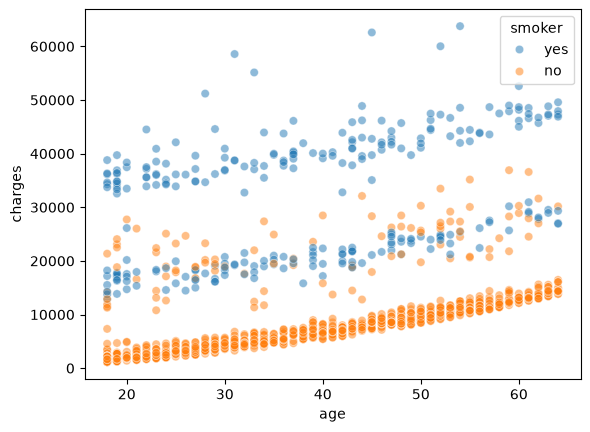

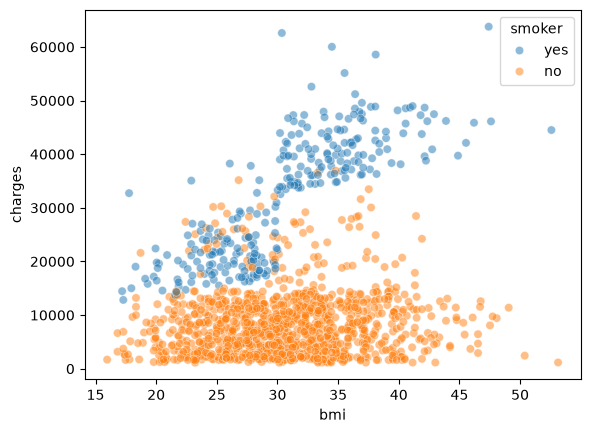

Yes. Smokers pay higher charges than non-smokers of the same age, and the gap stays roughly constant across ages, so age and smoking act mostly additively.
Yes. BMI interacts with smoking: among smokers, charges rise with BMI (especially above 30), while non-smokers' charges stay mostly flat regardless of BMI.


In [35]:
#Are there interactions between smoker, age, and bmi that appear to explain high charges?
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, alpha=0.5)
plt.show()
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, alpha=0.5)
plt.show()
print("Yes. Smokers pay higher charges than non-smokers of the same age, and the gap stays roughly constant across ages, "
      "so age and smoking act mostly additively.")
print("Yes. BMI interacts with smoking: among smokers, charges rise with BMI (especially above 30), "
      "while non-smokers' charges stay mostly flat regardless of BMI.")

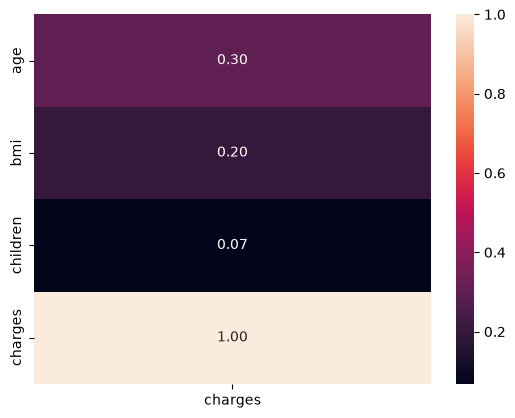

age have the strongest corr with charges


In [36]:
numerical_features_charges_corr = df[numerical_features].corr()[['charges']]
sns.heatmap(numerical_features_charges_corr, annot=True, fmt='0.2f')
plt.show()
print('age have the strongest corr with charges')

In [37]:
#Can you identify a group of customers with exceptionally high medical costs? - What do they have in common?
outliers.describe()

,age,bmi,children,charges
count,139.000000,139.000000,139.000000,139.000000
mean,41.079137,35.564604,1.187050,42103.947206
std,13.801420,4.434917,1.126546,5582.168107
min,18.000000,22.895000,0.000000,34617.840650
25%,30.000000,32.667500,0.000000,37786.149950
50%,43.000000,35.200000,1.000000,40974.164900
75%,52.500000,37.660000,2.000000,45786.706425
max,64.000000,52.580000,4.000000,63770.428010


In [38]:
for feature in outliers.columns:
  if feature in categorical_features:
    print(outliers[feature].value_counts(normalize=True) * 100)

sex
male      64.028777
female    35.971223
Name: proportion, dtype: float64
smoker
yes    97.841727
no      2.158273
Name: proportion, dtype: float64
region
southeast    41.007194
southwest    24.460432
northeast    20.143885
northwest    14.388489
Name: proportion, dtype: float64


In [39]:
print("""
Customers with exceptionally high charges (139 outliers, about 10%) mostly share:
- smoking status: 98% are smokers
- high BMI: median 35.2, and about 75% are 32.7 or above
Other traits are less consistent: 64% are male, 41% live in the southeast,
and they span all ages (18-64) with 0-4 children.
""")


Customers with exceptionally high charges (139 outliers, about 10%) mostly share:
- smoking status: 98% are smokers
- high BMI: median 35.2, and about 75% are 32.7 or above
Other traits are less consistent: 64% are male, 41% live in the southeast,
and they span all ages (18-64) with 0-4 children.



# clean data

In [40]:
print(df.duplicated().sum())
print(len(df))
df = df.drop_duplicates()
print(df.duplicated().sum())
print(len(df))

1
1338
0
1337


# Model Pipeline

In [42]:
X = df.drop(columns=['age_bins', 'charges'])
y = df['charges']

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=24)

In [44]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1069, 6)
(1069,)
(268, 6)
(268,)


In [45]:
numerical_features_for_model = [col for col in numerical_features if col != 'charges']
preprocessing = ColumnTransformer(
    transformers=[
        ('Scalar', StandardScaler(), numerical_features_for_model),
         ('Encoder', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='drop'
)

In [46]:
full_pipeline = Pipeline([
    ('preprocessor', preprocessing),
    ('model', 'passthrough')
])

In [ ]:
param_grid = [
    {
        'model': [LinearRegression()],
    },
     {
        'model': [DecisionTreeRegressor()],
        'model__max_depth':[2, 3, 4, 5, 6, 8, 10],
        'model__min_samples_leaf': [2, 5, 10, 20]
     },
    {
        'model': [RandomForestRegressor()],
        'model__n_estimators': [50, 100, 150, 200, 250, 300],
        'model__max_depth':[2, 3, 4, 5, 6, 8, 10],
        'model__min_samples_leaf': [2, 5, 10, 20]
    }
]
grid = GridSearchCV(
    full_pipeline, 
    param_grid, 
    cv=5, 
    scoring='r2'
)

In [49]:
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...assthrough')])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'model': [LinearRegression()]}, {'model': [DecisionTreeRegressor()], 'model__max_depth': [2, 3, ...], 'model__min_samples_leaf': [2, 5, ...]}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for ca

In [50]:
y_pred = grid.predict(X_test)
print(root_mean_squared_error(y_test, y_pred))
print(mean_absolute_error(y_test, y_pred))
print(r2_score(y_test, y_pred))

4570.989668737553
2612.35546058217
0.8768401107931549


In [51]:
grid.best_params_

{'model': RandomForestRegressor(),
 'model__max_depth': 4,
 'model__min_samples_leaf': 5,
 'model__n_estimators': 300}

In [56]:
scoring_model = pd.DataFrame({'score':grid.cv_results_['mean_test_score'],'model': grid.cv_results_['param_model']})
scoring_model['model'] = scoring_model['model'].apply(lambda a: type(a).__name__)

In [57]:
scoring_model['model'].unique()

<ArrowStringArray>
['LinearRegression', 'DecisionTreeRegressor', 'RandomForestRegressor']
Length: 3, dtype: str

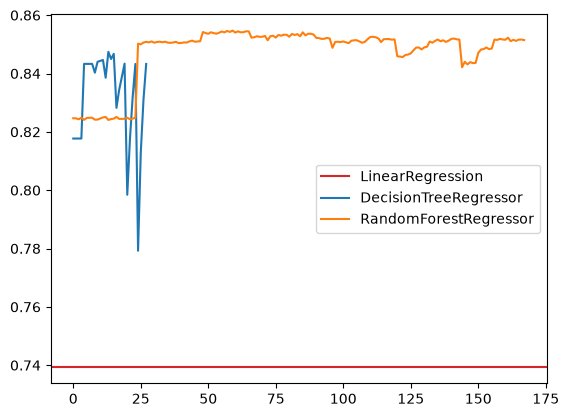

In [58]:
for model in ['LinearRegression', 'DecisionTreeRegressor', 'RandomForestRegressor']:
  plot_model = scoring_model[scoring_model['model'] == model].reset_index(drop=True)
  if len(plot_model) == 1:
    plt.axhline(plot_model['score'][0], color='tab:red', label=model)
  else:
    plt.plot(plot_model['score'], label=model)
  plt.legend()
plt.show()

# Save The Model and Features (Data Types)

In [64]:
best_model = grid.best_estimator_
joblib.dump(best_model, "./best_model.joblib")

['./best_model.joblib']

In [63]:
features_types = X.dtypes.astype(str).to_dict()
for feature, itstype in features_types.items():
    if itstype == 'str':
        features_types[feature] = X[feature].dropna().unique().tolist()
joblib.dump(features_types, "./features_types.joblib")

['./features_types.joblib']

# Load The Model

In [65]:
best_model = joblib.load("./best_model.joblib")

In [71]:
one_sample = X_test.iloc[0, :]
one_sample = one_sample.to_frame().T
one_sample

,age,sex,bmi,children,smoker,region
454,32,male,46.53,2,no,southeast


In [72]:
best_model.predict(one_sample)

array([6611.26990402])

In [75]:
y_test.iloc[0]

np.float64(4686.3887)

**reset_index()**

create new defualt index for the dataframe and convert the old index into new column in the data frame

**reset_index(drop=True)**

means:
- Create a new default index → 0, 1, 2, 3, ...
- Discard the old index → don't keep it as a column